# KITScenes — Sensors and calibration

The vehicle carries nine cameras, seven lidars, three radars and a GNSS/INS. This notebook shows how they are
calibrated to one another, how to move points between their frames, and what the API does for you on the way: lidar
deskewing, lidar points of several frames in one cloud, and radar ego-motion compensation.

**Needs:** `kitscenes[viz]` installed as in the README and a scene with its cameras and lidars; the voxel map of
section 8 also needs `kitscenes[torch]` (its cell is skipped without torch).
The example scene and how to download it alone: notebook 01.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

In [2]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
scene = ds[SCENE_ID]
frame = scene[min(50, len(scene) - 1)]
print(scene.info)

SceneInfo(scene_id='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', split='val', city='Frankfurt', lidar='velodyne', num_frames=220, recording_week='2025-W34', time_of_day='afternoon', light='day', sun_below_horizon=False, dark=False, recording_order=779, drive=11, order_in_drive=258, rig='velodyne_2025', sd_snapshot='Frankfurt_2025-W34.osm.pbf', duration_s=21.9, distance_m=174.0, mean_speed_mps=8.0, max_speed_mps=10.0, road_motorway_share=0.0, road_arterial_share=1.0, road_local_share=0.0, road_service_share=0.0, road_unmatched_share=0.0, road_dominant='arterial', speed_limit_kph_median=50.0, weather='partly_cloudy', road_surface='dry', weather_confidence='high')


## 1. The rig

`scene.rig` holds every calibrated sensor (from `calibration/calib.json`): cameras with intrinsics `K` and
`image_size` (width, height), and for every sensor `T_base_sensor`, the (4, 4) transform from the sensor frame into
the vehicle's base frame (x forward, y left, z up). Transforms are named `T_<to>_<from>` throughout the API.

In [3]:
rig = scene.rig
print(rig)
print(f"{'camera':30s} {'fx (px)':>8s} {'cx':>7s} {'cy':>7s} {'size':>12s}")
for name, cam in rig.cameras.items():
    print(f"{name:30s} {cam.K[0, 0]:8.1f} {cam.K[0, 2]:7.1f} {cam.K[1, 2]:7.1f} {str(cam.image_size):>12s}")

Rig(cameras={9 Camera}, lidars={7 Lidar}, radars={3 Radar}, transforms={25 items})
camera                          fx (px)      cx      cy         size
camera_base_front_center         3022.0  2924.0  1545.0 (5856, 3104)
camera_base_front_left_rect      1843.0  1139.0  1754.0 (2272, 3488)
camera_base_front_right_rect     1843.0  1139.0  1754.0 (2272, 3488)
camera_ring_front                1841.0  1740.0  1139.0 (3504, 2272)
camera_ring_front_left           1844.0  1764.0  1131.0 (3504, 2272)
camera_ring_front_right          1845.0  1749.0  1138.0 (3504, 2272)
camera_ring_rear                 1845.0  1765.0  1135.0 (3504, 2272)
camera_ring_rear_left            1843.0  1769.0  1136.0 (3504, 2272)
camera_ring_rear_right           1847.0  1756.0  1148.0 (3504, 2272)


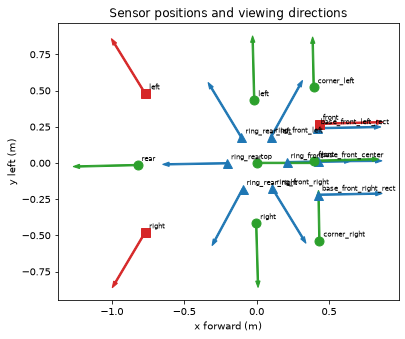

In [4]:
styles = {"camera": ("^", "tab:blue"), "lidar": ("o", "tab:green"), "radar": ("s", "tab:red")}
fig, ax = plt.subplots(figsize=(8, 5))
for kind, sensors in (("camera", rig.cameras), ("lidar", rig.lidars), ("radar", rig.radars)):
    marker, colour = styles[kind]
    for name, sensor in sensors.items():
        x, y = sensor.T_base_sensor[:2, 3]
        forward = sensor.T_base_sensor[:2, 2] if kind == "camera" else sensor.T_base_sensor[:2, 0]  # camera z / sensor x
        ax.plot(x, y, marker, color=colour, markersize=9)
        ax.arrow(x, y, *(0.4 * forward), color=colour, width=0.01)
        ax.annotate(name.split("_", 1)[1], (x, y), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set(aspect="equal", xlabel="x forward (m)", ylabel="y left (m)", title="Sensor positions and viewing directions")
plt.show()

## 2. Timing

Every sensor is resampled to the scene's 10 Hz timeline: frame `i` of each sensor belongs to `scene.timestamps_ns[i]`.
A sensor can miss frames (`scene.frame_indices(sensor)` lists the ones it has; a missing frame raises with state
`DROPPED`). A lidar sweep spans up to 0.1 s around the frame time (the per-point `timestamp`, seconds since the scene
start); a radar cloud is captured about 18 ms before it (`capture_t_ns`).

In [5]:
print(f"{'sensor':30s} {'frames':>6s}")
for name in scene.sensors:
    print(f"{name:30s} {len(scene.frame_indices(name)):6d} of {len(scene)}")

cloud = frame.lidar("lidar_top")
dt = cloud.attrs["timestamp"] - frame.t_s
radar = frame.radar("radar_front")
print(f"\nlidar_top points from {dt.min() * 1e3:+.0f} to {dt.max() * 1e3:+.0f} ms around the frame time")
print(f"radar_front captured {(radar.capture_t_ns - frame.t_ns) / 1e6:+.1f} ms from the frame time")

sensor                         frames
camera_base_front_center          220 of 220
camera_base_front_left_rect       220 of 220
camera_base_front_right_rect      220 of 220
camera_ring_front                 220 of 220
camera_ring_front_left            220 of 220
camera_ring_front_right           220 of 220
camera_ring_rear                  220 of 220
camera_ring_rear_left             220 of 220
camera_ring_rear_right            220 of 220
lidar_top                         220 of 220
lidar_front                       220 of 220
lidar_left                        220 of 220
lidar_right                       220 of 220
lidar_rear                        220 of 220
lidar_corner_left                 220 of 220
lidar_corner_right                220 of 220
radar_front                       220 of 220
radar_left                        220 of 220
radar_right                       220 of 220



lidar_top points from -52 to +52 ms around the frame time
radar_front captured -17.4 ms from the frame time


## 3. Cameras

The six ring cameras cover 360°; the three base cameras look ahead (a centre camera and a rectified stereo pair).
`reduce=8` keeps the thumbnails cheap.

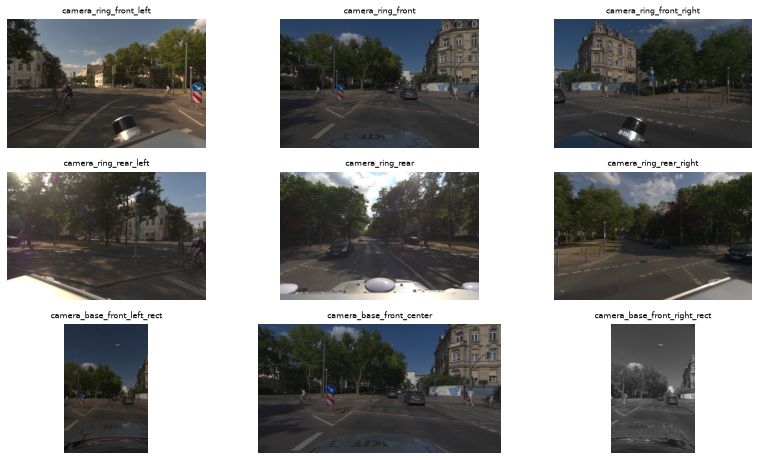

In [6]:
names = ["camera_ring_front_left", "camera_ring_front", "camera_ring_front_right",
         "camera_ring_rear_left", "camera_ring_rear", "camera_ring_rear_right",
         "camera_base_front_left_rect", "camera_base_front_center", "camera_base_front_right_rect"]
fig, axes = plt.subplots(3, 3, figsize=(12, 6.5))
for ax, name in zip(axes.flat, names):
    image = frame.image(name, reduce=8, missing="none")
    if image is not None:
        ax.imshow(image)
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Transforms

A point cloud can be had in the sensor frame (`frame="sensor"`), the base frame (default) or the world frame
(`frame="world"`). The transforms are plain matrices, so the conversion is one call of `kitscenes.transform_points`:

In [7]:
lidar = rig.lidars["lidar_top"]
in_sensor = frame.lidar("lidar_top", frame="sensor")
in_base = frame.lidar("lidar_top")
by_hand = kitscenes.transform_points(lidar.T_base_sensor, in_sensor.xyz)
print("max difference (m):", np.abs(by_hand - in_base.xyz).max())

in_world = kitscenes.transform_points(frame.T_world_base, in_base.xyz)
print("world frame, first point:", in_world[0], "| frame='world' gives the same:",
      np.allclose(in_world, frame.lidar("lidar_top", frame="world").xyz, atol=1e-3))
cam = rig.cameras["camera_ring_front"]
print("lidar_top -> camera_ring_front:\n", np.round(cam.T_sensor_base @ lidar.T_base_sensor, 3))

max difference (m): 0.0
world frame, first point: [ -540.3283  -1033.7943    153.84106] | frame='world' gives the same: True
lidar_top -> camera_ring_front:
 [[ 0.017 -1.     0.005  0.003]
 [ 0.002 -0.005 -1.    -0.183]
 [ 1.     0.017  0.002 -0.207]
 [ 0.     0.     0.     1.   ]]


**The road frame.** The base frame is on the roof, about 2 m above the road. Models and configs from nuScenes or
Argoverse 2 expect the ego frame on the ground; `frame="road"` is the base frame moved down by `scene.road_height_m`
(a constant per lidar generation, measured on the ground-labelled lidar points), with the same axes. The ground
labels (`labels=True`, notebook 03) show the road at z ≈ 0 in it (not in the test splits, which ship no labels):

In [8]:
print(f"road height {scene.road_height_m} m ({scene.info.lidar if scene.info else 'unknown'} lidar); T_road_base:\n", scene.T_road_base)
in_road = frame.lidar("lidar_top", frame="road", labels=True, missing="none")  # without labels: no "ground" column
if "ground" in in_road.attrs:
    near = in_road["ground"] & (np.linalg.norm(in_road.xyz[:, :2], axis=1) < 12)
    print(f"ground points within 12 m: median z {np.median(in_base.xyz[near, 2]):+.3f} m in the base frame, "
          f"{np.median(in_road.xyz[near, 2]):+.3f} m in the road frame")
print("pose of the road frame = T_world_base @ invert_transform(T_road_base):",
      np.allclose(frame.T_world_road, frame.T_world_base @ kitscenes.invert_transform(scene.T_road_base)))

road height 2.04 m (velodyne lidar); T_road_base:
 [[1.   0.   0.   0.  ]
 [0.   1.   0.   0.  ]
 [0.   0.   1.   2.04]
 [0.   0.   0.   1.  ]]
ground points within 12 m: median z -2.044 m in the base frame, -0.004 m in the road frame
pose of the road frame = T_world_base @ invert_transform(T_road_base): True


**Where the files are.** `frame.sensor_file(sensor)` locates a frame's stored file without reading it, for loaders
that take paths: in the release zips the zip, the member name and the byte range (the zips are uncompressed), in an
extracted scene the file itself.

In [9]:
where = frame.sensor_file("camera_ring_front")
print(where.path.name, where.offset, where.size, where.zip_member)
print("same bytes as frame.image_bytes:", where.read() == frame.image_bytes("camera_ring_front"))

0000000050.jpg 0 1489659 None
same bytes as frame.image_bytes: True


## 5. All lidars

`frame.fused_lidar()` fuses every lidar with data at this frame into one base-frame cloud of measured points;
`fused.sensor` names the lidars and `fused.source_index` says which one each point came from.

PointCloud(sensor=('lidar_top', 'lidar_front', 'lidar_left', 'lidar_right', 'lidar_rear', 'lidar_corner_left', 'lidar_corner_right'), n=710179, measured=710179, frame='base', t_ns=5051987968, compensated)


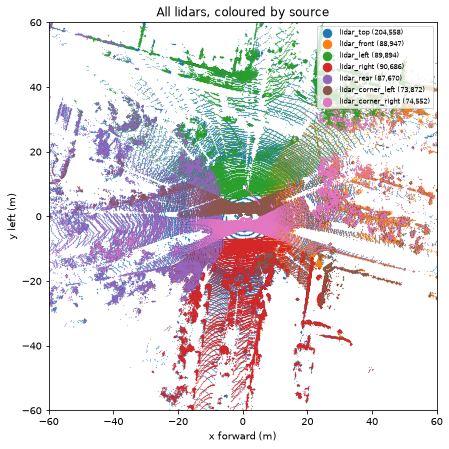

In [10]:
fused = frame.fused_lidar()
print(fused)
fig, ax = plt.subplots(figsize=(7, 7))
for i, name in enumerate(fused.sensor):
    pts = fused.xyz[fused.source_index == i]
    ax.scatter(pts[:, 0], pts[:, 1], s=0.02, color=plt.cm.tab10(i), label=f"{name} ({len(pts):,})")
ax.set(xlim=(-60, 60), ylim=(-60, 60), aspect="equal", xlabel="x forward (m)", ylabel="y left (m)",
       title="All lidars, coloured by source")
ax.legend(markerscale=60, fontsize=7, loc="upper right")
plt.show()

## 6. Lidar in the cameras

`camera.project(xyz)` maps base-frame points to pixels (`uv`, `depth` and a `visible` mask). For an image decoded with
`reduce=r`, project with `camera.scaled(1 / r)`. `render_frame` does the same for several cameras (`kitscenes.projection`),
colours by distance and draws the nearest points on top. Neither checks what the camera can see: the lidars sit
elsewhere, so points behind nearer ones are drawn too.

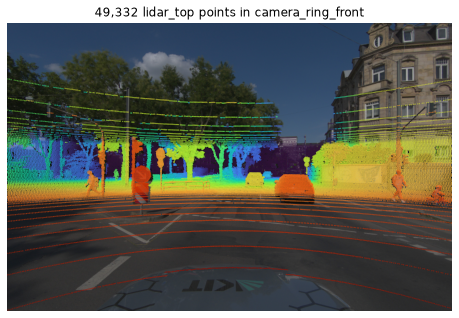

In [11]:
small = frame.image("camera_ring_front", reduce=4)
points = in_base.xyz  # lidar_top
uv, depth, visible = cam.scaled(1 / 4).project(points)
plt.figure(figsize=(8, 5.2))
plt.imshow(small)
plt.scatter(uv[visible, 0], uv[visible, 1], s=0.05, c=depth[visible], cmap="turbo_r", vmin=0, vmax=60)
plt.title(f"{visible.sum():,} lidar_top points in camera_ring_front")
plt.axis("off")
plt.show()

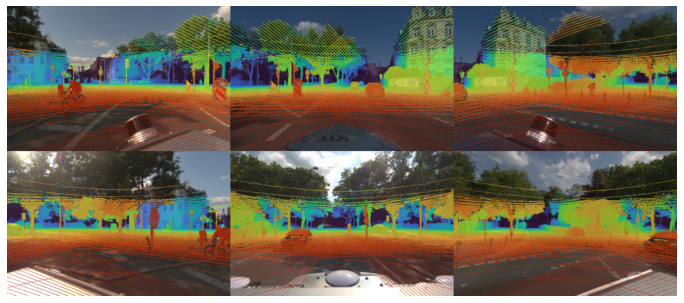

In [12]:
from kitscenes.visualization import camera_grid, render_frame

images = render_frame(frame, lidar=True, reduce=4)  # the six ring cameras, nearest points on top
grid = camera_grid(images, resize=0.5)
plt.figure(figsize=(12, 5.5))
plt.imshow(grid)
plt.axis("off")
plt.show()

## 7. Lidar deskewing

While a lidar spins (up to 0.1 s), the vehicle moves. `frame.lidar()` moves every point with the pose at its own
timestamp to the frame time; `deskew=False` only applies the extrinsic. The difference is up to speed × 0.1 s.

speed 7.9 m/s: deskewing moves the points by median 0.192 m, max 1.022 m (speed x 0.1 s = 0.79 m); motion compensated


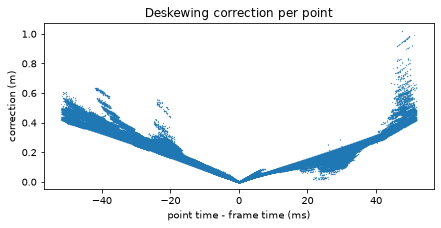

In [13]:
deskewed = frame.lidar("lidar_top")
plain = frame.lidar("lidar_top", deskew=False)
shift = np.linalg.norm(deskewed.xyz - plain.xyz, axis=1)  # the same points in the same order
speed = frame.ego().speed
print(f"speed {speed:.1f} m/s: deskewing moves the points by median {np.median(shift):.3f} m, "
      f"max {shift.max():.3f} m (speed x 0.1 s = {speed * 0.1:.2f} m); {deskewed.reason or 'motion compensated'}")

fig, ax = plt.subplots(figsize=(7, 3))
t = deskewed.attrs["timestamp"] - frame.t_s
ax.scatter(t * 1e3, shift, s=0.05)
ax.set(xlabel="point time - frame time (ms)", ylabel="correction (m)", title="Deskewing correction per point")
plt.show()

**Rows, scan layout and range images.** A sweep is stored as rows in the scan order of the lidar, and
`cloud.attrs["row"]` is the stored row of each point. Not every row holds a point. `rows=True` returns all rows:
those without a point stay at the sensor origin with `cloud.measured` False (reflectivity 0: OT128 slots its firing
pattern skips, zeroed near-field returns, empty Velodyne grid cells). `no_returns=True` (with `rows=True`) also
keeps the fired rays that returned nothing (reflectivity -1), flagged by `cloud.no_return`, each with its firing
time. The Hesai and Velodyne sweeps are organized; `cloud.layout` says how (the Hesai store columns, the Velodyne
rings, one after the other), and `cloud.range_image()` puts every row in its (return, ring, column) slot. Ring 0 is
the top laser; columns turn clockwise.

ScanLayout(model='Velodyne VLS-128 AP', order='ring-major', rings=128, columns=1708, returns=1, azimuth_step_deg=-0.2107728337236534)
218,624 rows: 204,558 points, 10,599 no-returns, 3,467 slots without a point


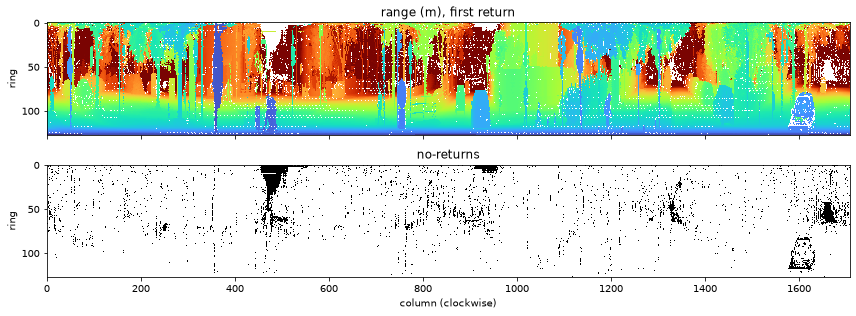

In [14]:
raw = frame.lidar("lidar_top", frame="sensor", deskew=False, rows=True, no_returns=True)
print(raw.layout)
print(f"{len(raw):,} rows: {int(raw.measured.sum()):,} points, {int(raw.no_return.sum()):,} no-returns, "
      f"{int((~raw.measured & ~raw.no_return).sum()):,} slots without a point")
ranges = raw.range_image()[0]  # first return; NaN where there is no point
no_return = raw.range_image(raw.no_return.astype(np.float32), fill=0)[0] > 0
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
axes[0].imshow(ranges, aspect="auto", cmap="turbo", vmin=0, vmax=60, interpolation="nearest")
axes[0].set(title="range (m), first return", ylabel="ring")
axes[1].imshow(no_return, aspect="auto", cmap="gray_r", interpolation="nearest")
axes[1].set(title="no-returns", xlabel="column (clockwise)", ylabel="ring")
plt.tight_layout()
plt.show()

## 8. Several frames in one cloud

`scene.accumulate(frames, voxel_size=...)` puts the lidar points of several frames into one frame: the world frame
by default, or the base or road frame of a `reference` frame. Every point is moved with the pose at its own time, so
static structure lines up and the cloud gets denser; whatever moved leaves a trail. `voxel_size` keeps one point per
cube, which bounds the size.

PointCloud(sensor=('lidar_top',), n=1640331, measured=1640331, frame='base', t_ns=5051987968, compensated)


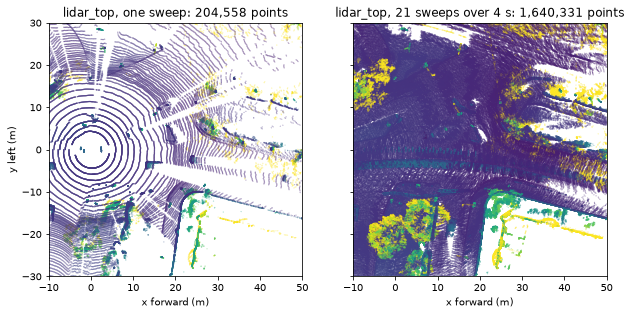

In [15]:
single = frame.lidar("lidar_top")
dense = scene.accumulate(range(frame.index - 20, frame.index + 21, 2), ["lidar_top"], frame="base",
                         reference=frame.index, voxel_size=0.1)
print(dense)
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, cloud, title in zip(axes, (single, dense), ("one sweep", f"{len(np.unique(dense['frame_index']))} sweeps over 4 s")):
    ax.scatter(cloud.xyz[:, 0], cloud.xyz[:, 1], s=0.02, c=cloud.xyz[:, 2], cmap="viridis", vmin=-3, vmax=3)
    ax.set(xlim=(-10, 50), ylim=(-30, 30), aspect="equal", xlabel="x forward (m)",
           title=f"lidar_top, {title}: {len(cloud):,} points")
axes[0].set_ylabel("y left (m)")
plt.show()

**A voxel map.** For many frames or several overlapping scenes, `kitscenes.mapping.VoxelMap` keeps one centroid
per voxel together with the number of frames that hit it and the longest run of consecutive frames (`run`). A wall
is hit frame after frame, a passing car only for an instant, so `to_cloud(min_run=3)` leaves the traffic out. It is
made for a GPU (`device="cuda"`, 5 cm voxels); the small map here (20 cm voxels, one lidar, a keyframe every 2 m)
runs on the CPU in a few seconds. More: `docs/lidar_maps.md`.

VoxelMap(1143146 voxels of 0.2 m, 1 scene(s), cpu) from 74 keyframes; 318,433 voxels were hit in 3 or more keyframes in a row


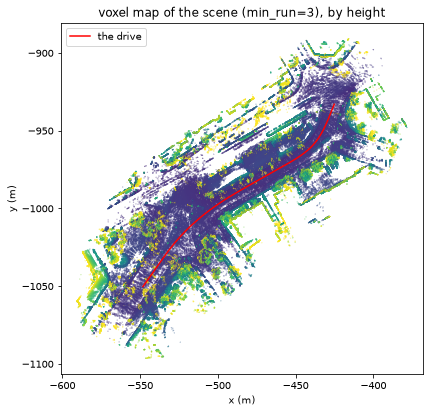

In [16]:
try:
    from kitscenes.mapping import VoxelMap, keyframes
except ImportError:  # no torch
    VoxelMap = None
if VoxelMap is not None:
    vmap = VoxelMap(voxel_size=0.2, device="cpu")
    stats = vmap.add_scene(scene, keyframes(scene, min_distance=2.0), ["lidar_top"], max_range=50)
    static = vmap.to_cloud(min_run=3)  # centroids in the world frame, with count, frames, run and reflectivity
    print(vmap, f"from {stats['frames']} keyframes; {len(static):,} voxels were hit in 3 or more keyframes in a row")
    drive = scene.track.xyz
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.scatter(static.xyz[:, 0], static.xyz[:, 1], s=0.03, c=static.xyz[:, 2] - drive[:, 2].mean(), cmap="viridis",
               vmin=-3, vmax=3)
    ax.plot(drive[:, 0], drive[:, 1], "r-", linewidth=1.5, label="the drive")
    ax.set(aspect="equal", xlabel="x (m)", ylabel="y (m)", title="voxel map of the scene (min_run=3), by height")
    ax.legend(loc="upper left")
    plt.show()

## 9. Radar and ego-motion compensation

`frame.radar(name)` is a `RadarCloud`: `xyz` in the base frame plus `range`, `azimuth`, `elevation` (relative to the
radar), `range_rate`, `rcs`, uncertainties and IDs. By default the positions are moved to the frame time and the ego
motion is removed from `range_rate`, so static returns read about 0 m/s; `compensate=False` gives the raw values.

RadarCloud(sensor='radar_front', n=504, measured=504, frame='base', t_ns=5051987968, compensated)


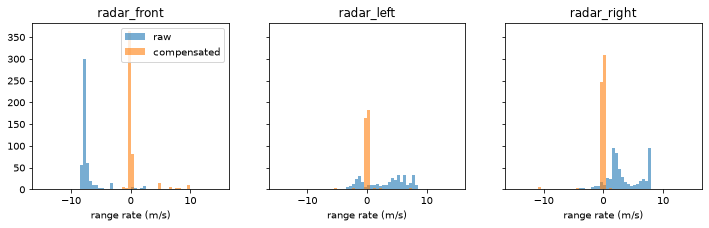

In [17]:
print(radar)
fig, axes = plt.subplots(1, len(frame.sensors("radar")), figsize=(12, 3), sharey=True)
bins = np.linspace(-15, 15, 61)
for ax, name in zip(np.atleast_1d(axes), frame.sensors("radar")):
    raw = frame.radar(name, compensate=False)["range_rate"]
    compensated = frame.radar(name)["range_rate"]
    ax.hist(raw, bins=bins, alpha=0.6, label="raw")
    ax.hist(compensated, bins=bins, alpha=0.6, label="compensated")
    ax.set(title=name, xlabel="range rate (m/s)")
axes[0].legend()
plt.show()

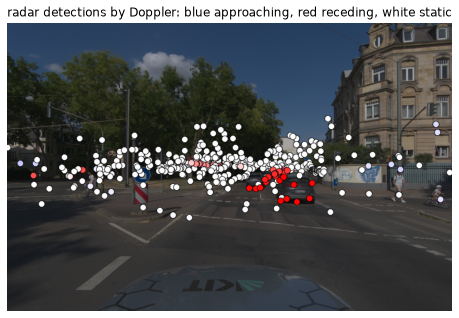

In [18]:
images = render_frame(frame, radar=True, cameras=["camera_ring_front"], reduce=4)
plt.figure(figsize=(8, 5.2))
plt.imshow(images["camera_ring_front"])
plt.title("radar detections by Doppler: blue approaching, red receding, white static")
plt.axis("off")
plt.show()

## 10. GNSS/INS and IMU

The GNSS/INS topics are `pyarrow` tables on the scene's timeline (`scene.message_topics(device)`,
`scene.messages(device, topic)`): each topic is one Parquet file, one row per message at the receiver's rate, with
`t_ns` (the message time), `t_sync_ns` (the time the extraction synchronized it to) and `frame_index` (the frame the
message is assigned to, else null). `rate="frame"` keeps one message per frame, with `index` = the frame index and
`t_sync_ns` = the frame's time. `scene.imu()` gives the 50 Hz gyro and accelerometer, rotated into the base frame
with `frame="base"`.

In [19]:
print("gnss topics:", scene.message_topics("gnss")[:8], "...")
fix = scene.messages("gnss", "navsatfix")
print(fix.num_rows, "fixes, e.g.", fix.select(["t_ns", "t_sync_ns", "frame_index", "latitude", "longitude", "altitude"]).slice(0, 1).to_pylist())
per_frame = scene.messages("gnss", "navsatfix", rate="frame")
frames = per_frame.column("index").to_numpy()
print(len(frames), "frames with a fix; synchronized to the frame times:",
      bool((per_frame.column("t_sync_ns").to_numpy() == scene.timestamps_ns[frames]).all()))
imu = scene.imu(frame="base")
print({k: v.shape for k, v in imu.items()})

gnss topics: ['aimplusstatus', 'attcoveuler', 'atteuler', 'basevectorcart', 'basevectorgeod', 'galauthstatus', 'gpsfix', 'gpst'] ...
220 fixes, e.g. [{'t_ns': 51987968, 't_sync_ns': 51987968, 'frame_index': 0, 'latitude': 50.10095140662768, 'longitude': 8.674529451569725, 'altitude': 146.31288701980844}]
220 frames with a fix; synchronized to the frame times: True
{'t_ns': (1096,), 'angular_velocity': (1096, 3), 'linear_acceleration': (1096, 3)}
